# Lab Assignment 10: NLP using Python-II

## Q1 & Q2: Text Processing, Tokenization, Stemming, and Lemmatization

In [7]:
import re
import nltk
from nltk.tokenize import word_tokenize, sent_tokenize
from nltk.corpus import stopwords
from nltk.probability import FreqDist
from nltk.stem import PorterStemmer, WordNetLemmatizer

nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')

paragraph = "Artificial intelligence is transforming the modern world at an unprecedented pace. Intelligent algorithms now power healthcare diagnostics and automate complex industrial processes. Machine learning systems learn from massive volumes of data to make highly accurate predictions. Deep neural networks process unstructured information like natural language and images with ease. This rapid evolution of technology brings both incredible opportunities and significant challenges."

cleaned_text = re.sub(r'[^\w\s]', '', paragraph.lower())

sentences = sent_tokenize(paragraph)
words_nltk = word_tokenize(cleaned_text)

words_split = cleaned_text.split()

print("NLTK Tokens:", words_nltk[:10])
print("Python Split:", words_split[:10])
print("Are they identical?:", words_nltk == words_split)

stop_words = set(stopwords.words('english'))
filtered_words = [w for w in words_nltk if w not in stop_words]

fdist = FreqDist(filtered_words)
print("Word Frequencies:", fdist.most_common(5))

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


NLTK Tokens: ['artificial', 'intelligence', 'is', 'transforming', 'the', 'modern', 'world', 'at', 'an', 'unprecedented']
Python Split: ['artificial', 'intelligence', 'is', 'transforming', 'the', 'modern', 'world', 'at', 'an', 'unprecedented']
Are they identical?: True
Word Frequencies: [('artificial', 1), ('intelligence', 1), ('transforming', 1), ('modern', 1), ('world', 1)]


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


In [9]:
import re
import nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, WordNetLemmatizer

nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')

paragraph = "Artificial intelligence is transforming the modern world at an unprecedented pace. Intelligent algorithms now power healthcare diagnostics and automate complex industrial processes. Machine learning systems learn from massive volumes of data to make highly accurate predictions. Deep neural networks process unstructured information like natural language and images with ease. This rapid evolution of technology brings both incredible opportunities and significant challenges."
stop_words = set(stopwords.words('english'))

alpha_words = re.findall(r'\b[a-zA-Z]+\b', paragraph.lower())
filtered_alpha = [w for w in alpha_words if w not in stop_words]

ps = PorterStemmer()
stemmed_words = [ps.stem(w) for w in filtered_alpha]

wnl = WordNetLemmatizer()
lemmatized_words = [wnl.lemmatize(w) for w in filtered_alpha]

for original, stem, lemma in zip(filtered_alpha[:10], stemmed_words[:10], lemmatized_words[:10]):
    print(f"{original:<15} -> Stem: {stem:<12} | Lemma: {lemma}")

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


artificial      -> Stem: artifici     | Lemma: artificial
intelligence    -> Stem: intellig     | Lemma: intelligence
transforming    -> Stem: transform    | Lemma: transforming
modern          -> Stem: modern       | Lemma: modern
world           -> Stem: world        | Lemma: world
unprecedented   -> Stem: unpreced     | Lemma: unprecedented
pace            -> Stem: pace         | Lemma: pace
intelligent     -> Stem: intellig     | Lemma: intelligent
algorithms      -> Stem: algorithm    | Lemma: algorithm
power           -> Stem: power        | Lemma: power


### Comparison between Stemming and Lemmatization

- **Stemming** uses heuristic rules to chop off the ends of words (e.g., 'transforming' becomes 'transform', but 'communities' might become 'commun'). It is faster but often produces non-dictionary words.
- **Lemmatization** uses vocabulary and morphological analysis to return the dictionary form (lemma) of a word (e.g., 'transforming' becomes 'transforming' or 'transform' depending on POS, and 'communities' becomes 'community'). It is grammatically accurate but computationally slower.
- **Preference**: Use stemming when speed is crucial and exact word syntax doesn't matter (e.g., search indexing). Use lemmatization when grammatical meaning and dictionary-valid words are necessary (e.g., sentiment analysis, chatbots).

## Q3: Bag of Words & TF-IDF

In [3]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
import numpy as np

texts = [
    "The new smartphone has an amazing camera and long battery life.",
    "Global stock markets experienced a significant drop amid economic uncertainty.",
    "The local team won the championship match after an exciting overtime play."
]

cv = CountVectorizer()
bow_rep = cv.fit_transform(texts)
print("Bag of Words Feature Names:\n", cv.get_feature_names_out())
print("Bag of Words Array:\n", bow_rep.toarray())

tfidf = TfidfVectorizer()
tfidf_rep = tfidf.fit_transform(texts)
feature_names = tfidf.get_feature_names_out()

for i, text in enumerate(texts):
    scores = tfidf_rep[i].toarray()[0]
    top_indices = np.argsort(scores)[-3:][::-1]
    top_keywords = [(feature_names[idx], round(scores[idx], 3)) for idx in top_indices]
    print(f"\nText {i+1}: '{text}'")
    print("Top 3 Keywords:", top_keywords)

Bag of Words Feature Names:
 ['after' 'amazing' 'amid' 'an' 'and' 'battery' 'camera' 'championship'
 'drop' 'economic' 'exciting' 'experienced' 'global' 'has' 'life' 'local'
 'long' 'markets' 'match' 'new' 'overtime' 'play' 'significant'
 'smartphone' 'stock' 'team' 'the' 'uncertainty' 'won']
Bag of Words Array:
 [[0 1 0 1 1 1 1 0 0 0 0 0 0 1 1 0 1 0 0 1 0 0 0 1 0 0 1 0 0]
 [0 0 1 0 0 0 0 0 1 1 0 1 1 0 0 0 0 1 0 0 0 0 1 0 1 0 0 1 0]
 [1 0 0 1 0 0 0 1 0 0 1 0 0 0 0 1 0 0 1 0 1 1 0 0 0 1 2 0 1]]

Text 1: 'The new smartphone has an amazing camera and long battery life.'
Top 3 Keywords: [('smartphone', np.float64(0.314)), ('new', np.float64(0.314)), ('long', np.float64(0.314))]

Text 2: 'Global stock markets experienced a significant drop amid economic uncertainty.'
Top 3 Keywords: [('uncertainty', np.float64(0.333)), ('stock', np.float64(0.333)), ('significant', np.float64(0.333))]

Text 3: 'The local team won the championship match after an exciting overtime play.'
Top 3 Keywords: [('the

## Q4: Text Similarity (Jaccard vs Cosine)

In [4]:
from sklearn.metrics.pairwise import cosine_similarity

tech_ai = "Artificial intelligence mimics human cognitive functions to solve complex problems. Machine learning algorithms analyze data patterns to make smart decisions. Deep learning models power computer vision and natural language tasks."
tech_blockchain = "Blockchain is a decentralized and distributed ledger technology that secures data. Cryptographic hashing ensures that transactional records cannot be altered. Smart contracts execute agreements automatically without central authorities."

def clean_and_tokenize(text):
    return set(re.sub(r'[^\w\s]', '', text.lower()).split())

tokens_ai = clean_and_tokenize(tech_ai)
tokens_bc = clean_and_tokenize(tech_blockchain)

intersection = tokens_ai.intersection(tokens_bc)
union = tokens_ai.union(tokens_bc)
jaccard = len(intersection) / len(union)
print("Jaccard Similarity:", jaccard)

vec = TfidfVectorizer()
tfidf_matrix = vec.fit_transform([tech_ai, tech_blockchain])
cosine = cosine_similarity(tfidf_matrix[0:1], tfidf_matrix[1:2])[0][0]
print("Cosine Similarity:", cosine)

Jaccard Similarity: 0.057692307692307696
Cosine Similarity: 0.050769175279468816


### Comparison of Metrics

- **Jaccard Similarity** only measures the presence or absence of words without accounting for word frequencies or term importance. It is highly sensitive to total unique vocabulary size.
- **Cosine Similarity** leveraging TF-IDF weights words based on their relative importance across the corpus and evaluates vector angles, making it a far superior metric for capturing subtle content and thematic similarities between texts.

## Q5: Sentiment Analysis and Word Cloud

Review: 'This wireless speaker has amazing sound quality and absolute durability!'
Polarity: 0.42 | Subjectivity: 0.73 | Label: Positive

Review: 'The product arrived late, was broken, and customer service was terrible.'
Polarity: -0.57 | Subjectivity: 0.67 | Label: Negative

Review: 'It is an average device, works as expected but nothing extraordinary.'
Polarity: 0.03 | Subjectivity: 0.60 | Label: Neutral

Review: 'Highly recommended! Best purchase I have made this year.'
Polarity: 0.60 | Subjectivity: 0.42 | Label: Positive

Review: 'Extremely satisfied with the fast shipping and stellar performance.'
Polarity: 0.32 | Subjectivity: 0.62 | Label: Positive



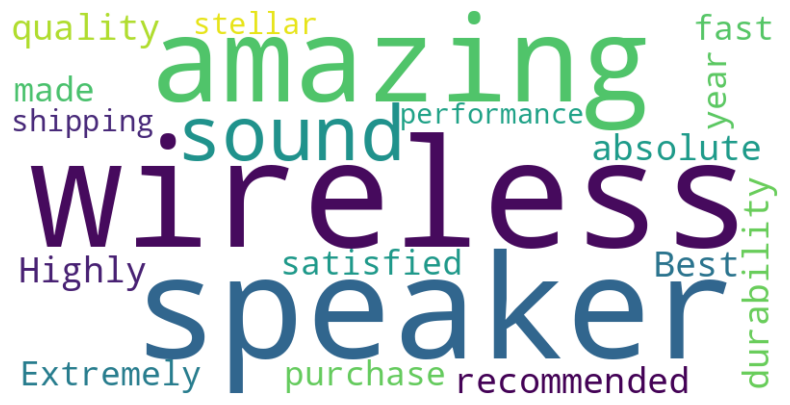

In [5]:
from textblob import TextBlob
import matplotlib.pyplot as plt
from wordcloud import WordCloud

reviews = [
    "This wireless speaker has amazing sound quality and absolute durability!",
    "The product arrived late, was broken, and customer service was terrible.",
    "It is an average device, works as expected but nothing extraordinary.",
    "Highly recommended! Best purchase I have made this year.",
    "Extremely satisfied with the fast shipping and stellar performance."
]

positive_reviews_text = ""

for r in reviews:
    analysis = TextBlob(r)
    polarity = analysis.sentiment.polarity
    subjectivity = analysis.sentiment.subjectivity

    if polarity > 0.1:
        sentiment = "Positive"
        positive_reviews_text += " " + r
    elif polarity < -0.1:
        sentiment = "Negative"
    else:
        sentiment = "Neutral"

    print(f"Review: '{r}'")
    print(f"Polarity: {polarity:.2f} | Subjectivity: {subjectivity:.2f} | Label: {sentiment}\n")

wordcloud = WordCloud(width=800, height=400, background_color='white').generate(positive_reviews_text)
plt.figure(figsize=(10, 5))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.show()

## Q6: Text Generation using LSTM

In [8]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense

training_data = "Artificial intelligence is reshaping industries by automating redundant tasks and generating new capabilities. Intelligent models learn patterns from text to write creative stories and develop software. Neural networks simulate human brain behavior to process complex sensory inputs and make logical predictions. This technology advances daily, creating opportunities across global education, finance, and medicine."

tokenizer = Tokenizer()
tokenizer.fit_on_texts([training_data])
total_words = len(tokenizer.word_index) + 1

input_sequences = []
for line in training_data.split('.'):
    token_list = tokenizer.texts_to_sequences([line])[0]
    for i in range(1, len(token_list)):
        n_gram_sequence = token_list[:i+1]
        input_sequences.append(n_gram_sequence)

max_sequence_len = max([len(x) for x in input_sequences])
input_sequences = np.array(pad_sequences(input_sequences, maxlen=max_sequence_len, padding='pre'))

X, y = input_sequences[:,:-1], input_sequences[:,-1]
y = to_categorical(y, num_classes=total_words)

model = Sequential([
    Embedding(total_words, 10, input_length=max_sequence_len-1),
    LSTM(50),
    Dense(total_words, activation='softmax')
])

model.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])
model.fit(X, y, epochs=150, verbose=0)

seed_word = "intelligent"
next_words = 15
output_text = seed_word

for _ in range(next_words):
    token_list = tokenizer.texts_to_sequences([output_text])[0]
    token_list = pad_sequences([token_list], maxlen=max_sequence_len-1, padding='pre')
    predicted = np.argmax(model.predict(token_list, verbose=0), axis=-1)[0]
    output_word = ""
    for word, index in tokenizer.word_index.items():
        if index == predicted:
            output_word = word
            break
    output_text += " " + output_word

print("Generated Text:\n", output_text)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Generated Text:
 intelligent models models patterns patterns from to write creative stories and develop software predictions predictions predictions
